# 01 · One world

**What you will see:** the SO-101 arm and a Unitree G1 created as two `Robot`s that land in the SAME simulated world;
observe, act and set_pose; a camera; both robots moving in one video; and the one run loop, for one robot and for many.

In [1]:
import math, time
import numpy as np
import _nb

def joints(o):
    return {k: round(float(v), 3) for k, v in zip(o.joints.names, o.joints.positions)}
from strands_robots import Description, Policy, Robot, Simulation
_nb.show(_nb.drawing("v01_one_world"))

## What a robot is, before any world

`Description.load(name)` resolves the model file from the registry and reads its joints, actuators and limits from the
model itself. The facts a bus needs (driver, LeRobot type and norm modes, what to do on disconnect) are registry data.

In [2]:
d = Description.load("so101")
_nb.show(_nb.table([
    {"fact": "name / format / category", "value": f"{d.name} / {d.format} / {d.category}"},
    {"fact": "device type", "value": d.device_type},
    {"fact": "model file", "value": f"`{d.model_path.name}` in `{d.package_dir.name}/`"},
    {"fact": "dof / action_keys", "value": f"{d.dof}: " + ", ".join(d.action_keys)},
    {"fact": "floating base / keyframes", "value": f"{d.floating} / {list(d.keyframes)}"},
    {"fact": "gripper", "value": f"keys {d.gripper.keys}, closed={d.gripper.closed}, open={d.gripper.open}"},
    {"fact": "hardware.driver / lerobot_type", "value": f"{d.hardware.driver} / {d.hardware.lerobot_type}"},
    {"fact": "hardware.lerobot_norm", "value": dict(d.hardware.lerobot_norm)},
    {"fact": "hardware.on_disconnect / position_hold", "value": f"{d.hardware.on_disconnect} / {d.hardware.position_hold}"},
]))
_nb.show(_nb.table([{"joint": j, "lo (deg)": f"{math.degrees(lo):.1f}", "hi (deg)": f"{math.degrees(hi):.1f}"}
                    for j, (lo, hi) in d.limits.items()]))

| fact | value |
|---|---|
| name / format / category | so101 / mjcf / arm |
| device type | robot_arm |
| model file | `so101_new_calib.xml` in `SO101/` |
| dof / action_keys | 6: shoulder_pan, shoulder_lift, elbow_flex, wrist_flex, wrist_roll, gripper |
| floating base / keyframes | False / [] |
| gripper | keys ('gripper',), closed=low, open=high |
| hardware.driver / lerobot_type | feetech / so101_follower |
| hardware.lerobot_norm | {'*': 'range_m100_100', 'gripper': 'range_0_100'} |
| hardware.on_disconnect / position_hold | hold / True |

| joint | lo (deg) | hi (deg) |
|---|---|---|
| shoulder_pan | -110.0 | 110.0 |
| shoulder_lift | -100.0 | 100.0 |
| elbow_flex | -100.0 | 90.0 |
| wrist_flex | -95.0 | 95.0 |
| wrist_roll | -160.0 | 160.0 |
| gripper | -10.0 | 100.0 |

## Two robots, one world

`Robot("so101")` joins `Simulation.default()`. The G1 given no world joins the same one, so there is one clock and one
physics step for both. Ids are unique in the world.

In [3]:
arm = Robot("so101")
g1 = Robot("g1", position=[0.7, 0.3, 0], keyframe="stand")
sim = arm.sim
assert arm.sim is g1.sim is Simulation.default()
print(sim)
print("ids:", list(sim.robots), "| physics:", sim.physics, "| control_dt:", sim.physics.timestep * sim.physics.substeps, "s")
print("a second arm would be:", Robot("so101", position=[0, -0.4, 0]).id)
sim.robots["so101_2"].close()
print("after close:", list(sim.robots))

Simulation('mujoco', physics='native', robots=['so101', 'unitree_g1'], t=0.000)
ids: ['so101', 'unitree_g1'] | physics: Physics(name='mujoco', timestep=0.002, substeps=10) | control_dt: 0.02 s
a second arm would be: so101_2
after close: ['so101', 'unitree_g1']


## observe, act, set_pose

`observe()` returns joints (rad), the base pose and the images of cameras attached to the robot. `act()` writes targets for
this body (missing joints hold, every target clipped to its limits) and advances the whole world one control step.

In [4]:
o = arm.observe()
print("t =", o.t, "| joints:", joints(o))
t0 = sim.time
for _ in range(40):
    o = arm.act({"shoulder_pan": 0.5, "shoulder_lift": -0.4, "elbow_flex": 0.5})
print(f"after 40 act() calls: t = {sim.time:.2f} s (+{sim.time - t0:.2f})")
print("joints:", joints(o))
print("the G1 shares that clock:", round(g1.observe().t, 2), "s")
try:
    arm.act({"elbo_flex": 0.1})
except KeyError as e:
    print("unknown joint refused:", e)
o = arm.act({"elbow_flex": 9.0})
print("elbow_flex=9.0 is clipped to its limit; reads", round(float(o.joints.positions[2]), 3), "rad")

t = 0.0 | joints: {'shoulder_pan': 0.0, 'shoulder_lift': 0.0, 'elbow_flex': 0.0, 'wrist_flex': 0.0, 'wrist_roll': 0.0, 'gripper': 0.0}
after 40 act() calls: t = 0.80 s (+0.80)
joints: {'shoulder_pan': 0.502, 'shoulder_lift': -0.379, 'elbow_flex': 0.526, 'wrist_flex': 0.064, 'wrist_roll': 0.0, 'gripper': -0.0}
the G1 shares that clock: 0.8 s
unknown joint refused: "unknown joint(s) ['elbo_flex'] for so101; action_keys are ['shoulder_pan', 'shoulder_lift', 'elbow_flex', 'wrist_flex', 'wrist_roll', 'gripper']"
elbow_flex=9.0 is clipped to its limit; reads 0.546 rad


In [5]:
before = sim.revision
arm.set_pose(position=[0.0, -0.05, 0.0])
print("arm base:", arm.pose.position, "| scene revision", before, "->", sim.revision, "| time did not advance:", round(sim.time, 2))
print("joint state survived the rebuild:", joints(arm.observe()))

arm base: [ 0.   -0.05  0.  ] | scene revision 4 -> 5 | time did not advance: 0.82
joint state survived the rebuild: {'shoulder_pan': 0.502, 'shoulder_lift': -0.38, 'elbow_flex': 0.546, 'wrist_flex': 0.065, 'wrist_roll': 0.0, 'gripper': -0.0}


## One loop

`robot.run(policy, hz=, seconds=|steps=|stop_when=)` is the loop written once: observe → policy → act. A bare callable is a
policy. It returns a `RunResult` with what it measured. In a world, `hz` sets how many physics steps each act advances and
time is sim time (`realtime=True` paces to the wall clock).

In [6]:
_nb.show(_nb.drawing("d03_one_loop"))
r = arm.run(lambda obs: {"shoulder_pan": -0.6, "elbow_flex": 0.2}, hz=50, seconds=2)
print(r.__class__.__name__, {k: getattr(r, k) for k in ("steps", "seconds", "hz_target", "stopped_by", "recorded", "fault")})
print(f"hz_achieved {r.hz_achieved:.0f} (faster than real time: sim time, no pacing)")
print("final:", joints(r.final))
r = arm.run(lambda obs: {"gripper": 1.2}, hz=30, stop_when=lambda obs: obs.joints.positions[5] > 1.0)
print("stop_when:", r.steps, "steps, stopped_by =", r.stopped_by, "| gripper", round(float(r.final.joints.positions[5]), 3))

RunResult {'steps': 100, 'seconds': 2.0, 'hz_target': 50.0, 'stopped_by': 'steps', 'recorded': None, 'fault': None}
hz_achieved 2346 (faster than real time: sim time, no pacing)
final: {'shoulder_pan': -0.601, 'shoulder_lift': 0.553, 'elbow_flex': 0.208, 'wrist_flex': 0.183, 'wrist_roll': -0.0, 'gripper': -0.0}
stop_when: 7 steps, stopped_by = stop_when | gripper 1.052


`run` refuses to start without a limit, and the same loop runs in the background with `start()`; `stop()` returns its result (no cameras exist yet; they come next).

In [7]:
try:
    arm.run(lambda obs: {})
except ValueError as e:
    print("refused:", e)
task = arm.start(lambda obs: {"wrist_roll": math.sin(obs.t)}, hz=50, realtime=True, seconds=30)
time.sleep(0.5)
r = arm.stop()
print("start/stop:", r.steps, "steps,", f"{r.seconds:.2f} s, stopped_by = {r.stopped_by}")

refused: run needs seconds=, steps= or stop_when=


start/stop: 26 steps, 0.52 s, stopped_by = stopped


## A camera

A world camera sees the whole scene. A camera attached to a robot moves with its base and shows up in that robot's
observations, which is what a policy gets.

cameras: ['front', 'arm_cam'] | in arm.observe().images: {'arm_cam': (180, 240, 3)}
in g1.observe().images: []



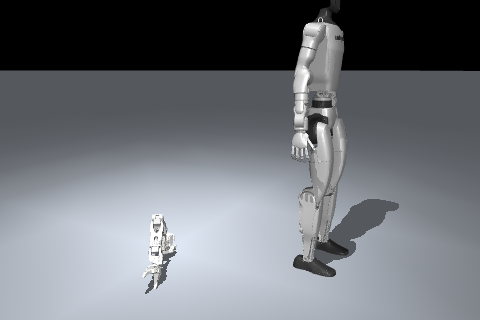
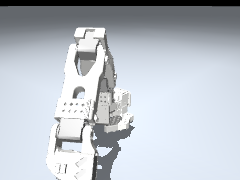

In [8]:
sim.camera("front", position=[1.25, -1.45, 0.95], target=[0.35, 0.15, 0.5], size=(480, 320))
sim.camera("arm_cam", position=[0.35, -0.35, 0.3], target=[0.05, 0, 0.12], attach="so101", size=(240, 180))
o = arm.observe()
print("cameras:", [c["name"] for c in sim.describe()["cameras"]], "| in arm.observe().images:", {k: v.shape for k, v in o.images.items()})
print("in g1.observe().images:", list(g1.observe().images))
_nb.show(_nb.image(sim.render("front"), o.images["arm_cam"]))

## Both robots move, one world

`sim.run({robot: policy, ...})` drives many robots in lock-step: every robot observes, every policy acts, the world steps
once. The arm follows a scripted wave; the G1 keeps itself standing with a whole-body controller (`Policy("holosoma")`,
see 02). The arm's function also grabs a frame every third step.

In [9]:
_nb.show(_nb.drawing("d02_one_world"))
frames = []
def wave(o):
    if round(o.t * 50) % 3 == 0:
        frames.append(sim.render("front"))
    return {"shoulder_pan": 0.9 * math.sin(2 * o.t), "elbow_flex": 0.5 + 0.5 * math.sin(3 * o.t), "shoulder_lift": -0.4}

wall = time.perf_counter()
results = sim.run({arm: wave, g1: Policy("holosoma")}, hz=50, seconds=6)
wall = time.perf_counter() - wall
for rid, r in results.items():
    print(f"{rid:11s} {r.steps} steps, {r.seconds:.1f} s sim, {r.hz_target:g} Hz, stopped_by={r.stopped_by}")
print(f"wall {wall:.1f} s | G1 pelvis height at the end: {g1.pose.position[2]:.3f} m | frames {len(frames)}")
assert g1.pose.position[2] > 0.7
_nb.video(frames, fps=17, width=480)

so101       300 steps, 6.0 s sim, 50 Hz, stopped_by=steps
unitree_g1  300 steps, 6.0 s sim, 50 Hz, stopped_by=steps
wall 8.8 s | G1 pelvis height at the end: 0.766 m | frames 100


In [10]:
results = sim.run({arm: lambda o: {"shoulder_pan": 0.0}, g1: Policy("holosoma")}, hz=50, steps=50)
print({k: (v.steps, v.stopped_by, round(v.final.t, 2)) for k, v in results.items()})
assert len({round(v.final.t, 6) for v in results.values()}) == 1, "one clock"
print("one clock: both robots ended at the same sim time")
sim.close()

{'so101': (50, 'steps', 10.58), 'unitree_g1': (50, 'steps', 10.58)}
one clock: both robots ended at the same sim time


## Where this sits in v1

Parts 1-3 (types + Description, Simulation + MuJoCo, Robot as a class), merged on `dev`. Every later part plugs into this
world and this loop.